# 04 - Clustering : segmentation du marché (K-Means)

**Objectif** : regrouper les annonces en segments interprétables à partir
du **prix**, de l'**âge du véhicule** et du **kilométrage**, puis
sauvegarder le pipeline et la description des segments pour l'application.

**Entrée** : `data/cleaned/used_car_ads_clean.csv` (lecture seule).
**Sortie** : `artifacts/clustering/`.

**Critère de succès (Step 0)** : aucune métrique unique ne garantit la
qualité des clusters. Le silhouette score guide le choix de k, mais les
segments doivent surtout être **interprétables** et présenter des écarts
de prix lisibles.

In [1]:
import json
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import sklearn
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import silhouette_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

RANDOM_STATE = 42
ANNEE_REFERENCE = 2026  # année de la collecte (date_collecte = 2026-11-17), réutilisée par l'application
COULEUR, ENCRE, GRILLE = "#2a78d6", "#0b0b0b", "#e5e5e2"
format_dh = FuncFormatter(lambda x, _: f"{x:,.0f}".replace(",", " "))
def fmt(x):
    return f"{x:,.0f}".replace(",", " ")
def habiller(ax):
    ax.grid(color=GRILLE, linewidth=0.6); ax.set_axisbelow(True)
    for cote in ("top", "right"):
        ax.spines[cote].set_visible(False)

## 1. Variables de segmentation

- **`prix`** : prix réel de l'annonce (DH).
- **`age`** = `ANNEE_REFERENCE − annee`, avec `ANNEE_REFERENCE = 2026`,
  l'année de la collecte. Cette constante est sauvegardée et réutilisée à
  l'identique par l'application.
- **`kilometrage`** : 121 valeurs manquantes.

Ces variables sont calculées dans un DataFrame local `X`, sans modifier le
fichier nettoyé.

In [2]:
df = pd.read_csv("../data/cleaned/used_car_ads_clean.csv")
X = pd.DataFrame({
    "prix": df["prix"],
    "age": ANNEE_REFERENCE - df["annee"],
    "kilometrage": df["kilometrage"],
})
km_impute = X["kilometrage"].isna()
print(f"Annonces : {len(X)} — kilométrage manquant (sera imputé pour le clustering) : {km_impute.sum()}")
X.describe().round(0)

Annonces : 619 — kilométrage manquant (sera imputé pour le clustering) : 121


,prix,age,kilometrage
count,619.0,619.0,498.0
mean,266270.0,7.0,119261.0
std,205934.0,6.0,68870.0
min,16000.0,0.0,0.0
25%,145000.0,3.0,70000.0
50%,210000.0,5.0,113550.0
75%,316500.0,9.0,155000.0
max,1850000.0,46.0,413000.0


## 2. Pipeline de prétraitement + K-Means

1. **`prix` → `log1p`** : le prix est très asymétrique (asymétrie 3,09
   selon l'EDA). Sans le log, K-Means serait dominé par quelques véhicules
   de luxe.
2. **`kilometrage` → imputation par la médiane**. C'est nécessaire, car
   K-Means n'accepte pas les NaN, et cela évite de supprimer 19,5 % des
   annonces.
3. **`StandardScaler`** : met les trois variables à la même échelle.
4. **K-Means** (`n_init=10`, `random_state=42`).

Tout est intégré dans un seul pipeline, appliqué à l'identique aux
nouvelles observations dans l'application.

In [3]:
def construire_pipeline(k):
    return Pipeline([
        ("pretraitement", ColumnTransformer([
            ("log_prix", FunctionTransformer(np.log1p, inverse_func=np.expm1), ["prix"]),
            ("age", "passthrough", ["age"]),
            ("kilometrage", SimpleImputer(strategy="median"), ["kilometrage"]),
        ])),
        ("scaler", StandardScaler()),
        ("kmeans", KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)),
    ])

lignes = []
for k in range(2, 7):
    pipe = construire_pipeline(k).fit(X)
    Z = pipe[:-1].transform(X)
    etiquettes = pipe.named_steps["kmeans"].labels_
    lignes.append({"k": k, "silhouette": silhouette_score(Z, etiquettes),
                   "inertie": pipe.named_steps["kmeans"].inertia_,
                   "plus petit cluster": np.bincount(etiquettes).min()})
choix_k = pd.DataFrame(lignes).set_index("k")
print("Choix du nombre de clusters :")
choix_k.round(3)

Choix du nombre de clusters :


,silhouette,inertie,plus petit cluster
k,,,
2,0.433,1079.321,164
3,0.281,851.906,117
4,0.301,716.609,49
5,0.289,589.795,44
6,0.275,516.850,40


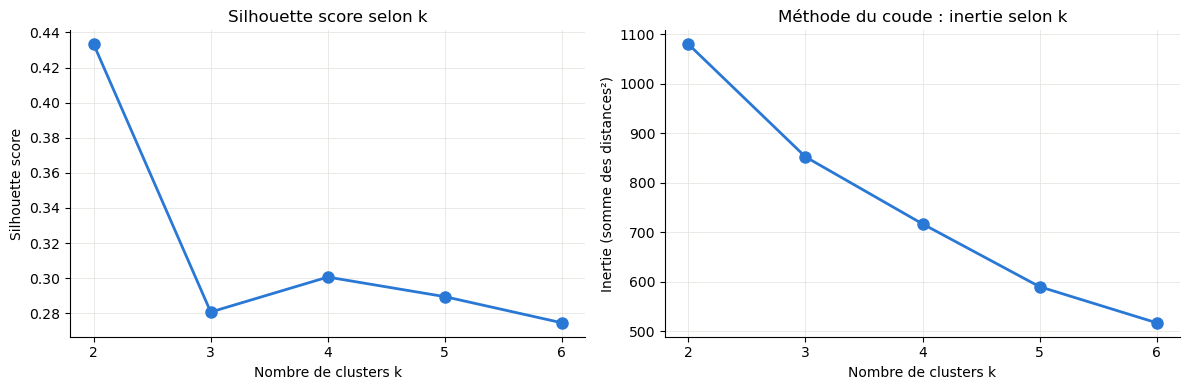

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(choix_k.index, choix_k["silhouette"], color=COULEUR, linewidth=2, marker="o", markersize=8)
axes[0].set_title("Silhouette score selon k")
axes[0].set_xlabel("Nombre de clusters k"); axes[0].set_ylabel("Silhouette score")
axes[1].plot(choix_k.index, choix_k["inertie"], color=COULEUR, linewidth=2, marker="o", markersize=8)
axes[1].set_title("Méthode du coude : inertie selon k")
axes[1].set_xlabel("Nombre de clusters k"); axes[1].set_ylabel("Inertie (somme des distances²)")
for a in axes:
    a.set_xticks(choix_k.index); habiller(a)
fig.tight_layout()
plt.show()

**Choix de k = 4**

- Le silhouette score est maximal pour **k = 2** (0,433), mais cette
  partition ne sépare que deux grands groupes : les véhicules anciens à
  fort kilométrage d'un côté, tout le reste de l'autre. Elle mélange donc
  le milieu de gamme récent et le premium, ce qui la rend peu utile pour
  décrire le marché.
- **k = 4** obtient le deuxième meilleur score (0,301). Ses 4 segments sont
  interprétables, avec des écarts de prix médian nets (voir les profils
  ci-dessous), et le plus petit cluster compte encore 49 annonces.
- Les scores pour k = 3, 5 et 6 sont plus faibles (de 0,275 à 0,289).

On retient donc k = 4 : c'est le meilleur compromis entre le silhouette
score et l'interprétabilité. Un silhouette d'environ 0,30 indique des
groupes qui se chevauchent en partie : ce sont des segments utiles, pas
des catégories nettement séparées.

In [5]:
K = 4  # voir la justification ci-dessus
pipeline = construire_pipeline(K).fit(X)
cluster = pd.Series(pipeline.named_steps["kmeans"].labels_, index=X.index, name="cluster")
print(f"k retenu : {K} — silhouette = {choix_k.loc[K, 'silhouette']:.3f}")
print(cluster.value_counts().sort_index().rename("annonces").to_string())

k retenu : 4 — silhouette = 0.301
cluster
0    316
1     49
2    177
3     77


## 3. Profils des clusters

Les statistiques sont calculées sur les **valeurs réelles** :
- le **kilométrage moyen et médian** ne porte que sur les annonces dont le
  kilométrage est renseigné ;
- la part de kilométrages imputés (manquants dans les données, complétés
  par la médiane pour le seul calcul des clusters) est donnée à part.

Les numéros de cluster sont arbitraires : on les **ordonne par prix
médian** et on décrit chaque segment à partir de ses statistiques.

In [6]:
MARQUES_PREMIUM = ["Porsche", "Land Rover", "Mercedes-Benz", "BMW", "Audi", "Jaguar", "Maserati", "Lexus", "Cadillac"]
donnees = df.assign(age=X["age"], cluster=cluster)  # copie locale enrichie, le CSV n'est pas modifié
profils = donnees.groupby("cluster").agg(
    annonces=("prix", "size"),
    prix_moyen=("prix", "mean"),
    prix_median=("prix", "median"),
    prix_q1=("prix", lambda s: s.quantile(0.25)),
    prix_q3=("prix", lambda s: s.quantile(0.75)),
    age_moyen=("age", "mean"),
    age_median=("age", "median"),
    km_moyen_renseigne=("kilometrage", "mean"),     # pandas ignore les NaN : valeurs réelles uniquement
    km_median_renseigne=("kilometrage", "median"),
    km_renseignes=("kilometrage", "count"),
)
profils["part_km_imputes_%"] = (1 - profils["km_renseignes"] / profils["annonces"]) * 100
profils["part_premium_%"] = donnees.groupby("cluster")["marque"].apply(lambda s: s.isin(MARQUES_PREMIUM).mean() * 100)
profils["marques_principales"] = donnees.groupby("cluster")["marque"].apply(
    lambda s: ", ".join(f"{m} ({n})" for m, n in s.value_counts().head(3).items()))
profils = profils.sort_values("prix_median")

affichage = pd.DataFrame({
    "annonces": profils["annonces"],
    "prix moyen (DH)": profils["prix_moyen"].map(fmt),
    "prix médian (DH)": profils["prix_median"].map(fmt),
    "prix Q1–Q3 (DH)": profils["prix_q1"].map(fmt) + " – " + profils["prix_q3"].map(fmt),
    "âge moyen (ans)": profils["age_moyen"].round(1),
    "km moyen (renseignés)": profils["km_moyen_renseigne"].map(fmt),
    "km renseignés": profils["km_renseignes"],
    "% km imputés": profils["part_km_imputes_%"].round(1),
    "% premium": profils["part_premium_%"].round(1),
    "marques principales": profils["marques_principales"],
})
print("Profils des clusters (triés par prix médian) :")
affichage

Profils des clusters (triés par prix médian) :


,annonces,prix moyen (DH),prix médian (DH),prix Q1–Q3 (DH),âge moyen (ans),km moyen (renseignés),km renseignés,% km imputés,% premium,marques principales
cluster,,,,,,,,,,
1,49,103 673,98 000,68 000 – 118 000,18.6,116 129,24,51.0,28.6,"Mercedes-Benz (7), Ford (6), Fiat (5)"
3,77,131 169,125 000,98 000 – 160 000,13.6,233 731,77,0.0,35.1,"Volkswagen (11), Mercedes-Benz (9), Land Rover..."
0,316,202 394,195 000,155 000 – 240 000,5.6,114 128,245,22.5,15.8,"Peugeot (35), Volkswagen (34), Renault (27)"
2,177,484 093,398 000,325 000 – 590 000,3.5,70 042,152,14.1,57.6,"Mercedes-Benz (31), Audi (22), Volkswagen (20)"


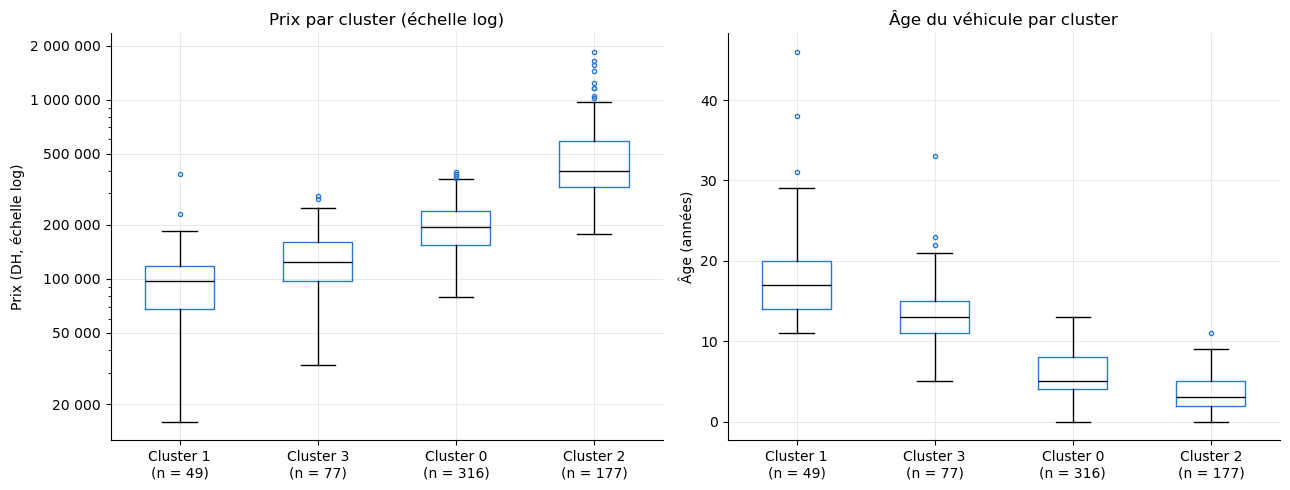

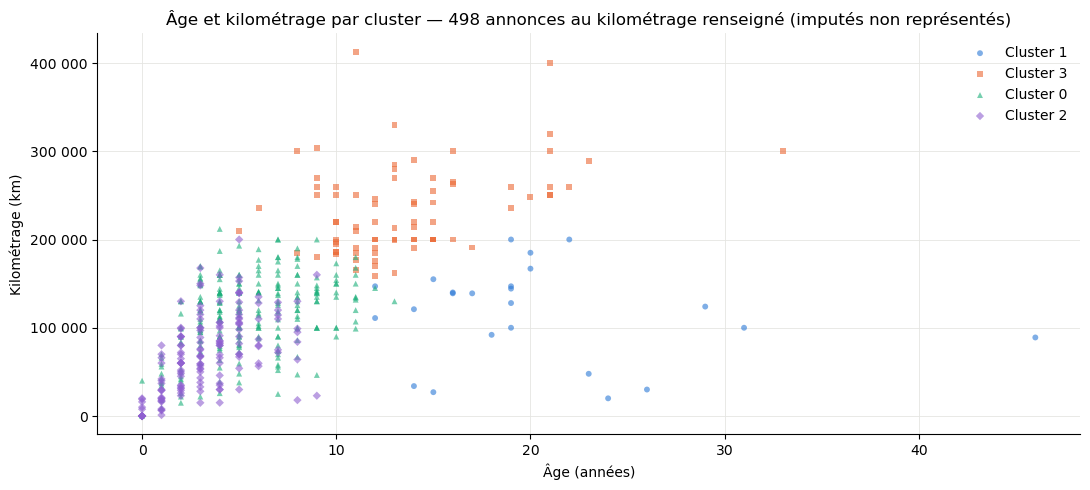

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ordre = profils.index.tolist()
for ax, (col, titre, unite) in zip(axes, [("prix", "Prix par cluster (échelle log)", "Prix (DH, échelle log)"),
                                          ("age", "Âge du véhicule par cluster", "Âge (années)")]):
    ax.boxplot([donnees.loc[donnees["cluster"] == c, col] for c in ordre], widths=0.5,
               tick_labels=[f"Cluster {c}\n(n = {profils.loc[c, 'annonces']})" for c in ordre],
               boxprops=dict(color=COULEUR), medianprops=dict(color=ENCRE),
               flierprops=dict(marker="o", markersize=3, markeredgecolor=COULEUR))
    ax.set_title(titre); ax.set_ylabel(unite); habiller(ax)
axes[0].set_yscale("log")
axes[0].set_yticks([20000, 50000, 100000, 200000, 500000, 1000000, 2000000])
axes[0].yaxis.set_major_formatter(format_dh); axes[0].yaxis.set_minor_formatter(FuncFormatter(lambda x, _: ""))
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(11, 5))
reel = donnees["kilometrage"].notna()
marqueurs = ["o", "s", "^", "D", "v", "P"]
for i, c in enumerate(ordre):
    sel = reel & (donnees["cluster"] == c)
    ax.scatter(donnees.loc[sel, "age"], donnees.loc[sel, "kilometrage"], s=18, marker=marqueurs[i],
               color=["#2a78d6", "#eb6834", "#1baf7a", "#8f5fd0", "#d4a20c", "#d0478c"][i], alpha=0.6,
               edgecolors="none", label=f"Cluster {c}")
ax.set_title(f"Âge et kilométrage par cluster — {reel.sum()} annonces au kilométrage renseigné (imputés non représentés)")
ax.set_xlabel("Âge (années)"); ax.set_ylabel("Kilométrage (km)")
ax.yaxis.set_major_formatter(format_dh)
ax.legend(frameon=False); habiller(ax)
fig.tight_layout()
plt.show()

## 4. Description des segments

Les noms et descriptions sont **déduits des statistiques observées**.
- **Gamme** : rang du prix médian (du segment le moins cher au plus cher).
- **Âge** : âge médian comparé à l'âge médian global.
- **Kilométrage** : kilométrage médian (valeurs renseignées) comparé à la
  médiane globale.

Un segment est un groupe d'annonces aux caractéristiques proches, pas une
catégorie de véhicules définie a priori.

In [8]:
age_global = X["age"].median()
km_global = X["kilometrage"].median()
noms_gamme = {2: ["Économique", "Haut de gamme"],
              3: ["Économique", "Intermédiaire", "Haut de gamme"],
              4: ["Entrée de gamme", "Économique", "Milieu de gamme", "Haut de gamme"],
              5: ["Très économique", "Économique", "Intermédiaire", "Supérieur", "Haut de gamme"],
              6: ["Très économique", "Économique", "Intermédiaire", "Intermédiaire supérieur", "Supérieur", "Haut de gamme"]}[K]

def qualifier(valeur, reference, bas, haut, ecart=0.25):
    if valeur < reference * (1 - ecart):
        return bas
    if valeur > reference * (1 + ecart):
        return haut
    return "moyen"

segments = {}
for rang, c in enumerate(ordre):
    p = profils.loc[c]
    age_q = qualifier(p["age_median"], age_global, "récents", "anciens")
    km_q = qualifier(p["km_median_renseigne"], km_global, "faible kilométrage", "fort kilométrage")
    age_txt = {"récents": "véhicules récents", "anciens": "véhicules anciens", "moyen": "véhicules d'âge moyen"}[age_q]
    km_txt = {"faible kilométrage": "faible kilométrage", "fort kilométrage": "kilométrage élevé", "moyen": "kilométrage moyen"}[km_q]
    nom = f"{noms_gamme[rang]} — {age_txt}, {km_txt}"
    description = (f"{age_txt.capitalize()} ({p['age_median']:.0f} ans en médiane), {km_txt} "
                   f"({fmt(p['km_median_renseigne'])} km en médiane), prix médian {fmt(p['prix_median'])} DH "
                   f"(moitié centrale entre {fmt(p['prix_q1'])} et {fmt(p['prix_q3'])} DH). "
                   f"Marques fréquentes : {p['marques_principales']}.")
    segments[int(c)] = {
        "nom": nom, "description": description,
        "annonces": int(p["annonces"]),
        "prix_median": float(p["prix_median"]), "prix_moyen": float(p["prix_moyen"]),
        "prix_q1": float(p["prix_q1"]), "prix_q3": float(p["prix_q3"]),
        "age_moyen": float(p["age_moyen"]), "age_median": float(p["age_median"]),
        "km_moyen_renseigne": float(p["km_moyen_renseigne"]), "km_median_renseigne": float(p["km_median_renseigne"]),
        "part_km_imputes_pct": float(p["part_km_imputes_%"]), "part_premium_pct": float(p["part_premium_%"]),
        "marques_principales": p["marques_principales"],
    }
print(f"Références globales : âge médian {age_global:.0f} ans, kilométrage médian {fmt(km_global)} km")
print()
for c in ordre:
    s = segments[int(c)]
    print(f"Cluster {c} — {s['nom']} ({s['annonces']} annonces)")
    print(f"  {s['description']}")
    print()

Références globales : âge médian 5 ans, kilométrage médian 113 550 km

Cluster 1 — Entrée de gamme — véhicules anciens, kilométrage moyen (49 annonces)
  Véhicules anciens (17 ans en médiane), kilométrage moyen (126 000 km en médiane), prix médian 98 000 DH (moitié centrale entre 68 000 et 118 000 DH). Marques fréquentes : Mercedes-Benz (7), Ford (6), Fiat (5).

Cluster 3 — Économique — véhicules anciens, kilométrage élevé (77 annonces)
  Véhicules anciens (13 ans en médiane), kilométrage élevé (220 000 km en médiane), prix médian 125 000 DH (moitié centrale entre 98 000 et 160 000 DH). Marques fréquentes : Volkswagen (11), Mercedes-Benz (9), Land Rover (6).

Cluster 0 — Milieu de gamme — véhicules d'âge moyen, kilométrage moyen (316 annonces)
  Véhicules d'âge moyen (5 ans en médiane), kilométrage moyen (120 000 km en médiane), prix médian 195 000 DH (moitié centrale entre 155 000 et 240 000 DH). Marques fréquentes : Peugeot (35), Volkswagen (34), Renault (27).

Cluster 2 — Haut de ga

**Interprétation des 4 segments** (chiffres tirés des profils ci-dessus)

| Cluster | Segment | Annonces | Prix médian | Âge médian | Km médian (renseignés) |
|---|---|---|---|---|---|
| 1 | Entrée de gamme — véhicules anciens | 49 | 98 000 DH | 17 ans | 126 000 km (24 valeurs) |
| 3 | Économique — anciens, kilométrage élevé | 77 | 125 000 DH | 13 ans | 220 000 km |
| 0 | Milieu de gamme — âge et kilométrage moyens | 316 | 195 000 DH | 5 ans | 120 000 km |
| 2 | Haut de gamme — récents, faible kilométrage | 177 | 398 000 DH | 3 ans | 68 750 km |

- Les prix médians augmentent nettement d'un segment à l'autre, de
  98 000 à 398 000 DH. Le segment haut de gamme compte 57,6 % de marques
  premium (hypothèse d'analyse de l'EDA).
- Les clusters 1 et 3 sont tous deux anciens. Le cluster 3 se distingue
  par un kilométrage très élevé, avec 0 % de kilométrage imputé.

**Limite importante — cluster 1** : **51 % de ses annonces ont un
kilométrage imputé.** Pour ces véhicules anciens, la médiane imputée
(environ 114 000 km) est probablement plus basse que leur kilométrage
réel. Une partie de ce segment est donc **façonnée par l'imputation**, qui
les sépare artificiellement du cluster 3 (anciens à fort kilométrage). Son
profil de kilométrage ne repose que sur 24 valeurs réelles. Il faut
l'interpréter avec prudence.

**Autres limites** :
- silhouette d'environ 0,30, donc des groupes qui se chevauchent en
  partie ;
- les segments décrivent la combinaison prix, âge et kilométrage, pas la
  marque (qui n'entre pas dans le clustering) ;
- dans l'application, le prix utilisé pour attribuer un segment est le
  **prix prédit** par la régression, et non un prix réel.

## 5. Sauvegarde des artefacts

- `pipeline_kmeans.joblib` : log du prix, imputeur du kilométrage, scaler
  et K-Means, dans un seul objet.
- `segments.json` : `ANNEE_REFERENCE`, k, silhouette, variables d'entrée,
  profils et descriptions par numéro de cluster.

In [9]:
DOSSIER = Path("../artifacts/clustering")
DOSSIER.mkdir(parents=True, exist_ok=True)
joblib.dump(pipeline, DOSSIER / "pipeline_kmeans.joblib")
meta = {
    "annee_reference": ANNEE_REFERENCE,
    "variables_entree": ["prix", "age", "kilometrage"],
    "k": int(K),
    "silhouette": float(choix_k.loc[K, "silhouette"]),
    "mediane_imputation_kilometrage": float(pipeline.named_steps["pretraitement"].named_transformers_["kilometrage"].statistics_[0]),
    "note_kilometrage": "Statistiques de km calculées sur les valeurs renseignées uniquement ; part de km imputés fournie séparément.",
    "segments": {str(c): s for c, s in segments.items()},
    "ordre_par_prix": [int(c) for c in ordre],
    "random_state": RANDOM_STATE,
    "version_sklearn": sklearn.__version__,
}
(DOSSIER / "segments.json").write_text(json.dumps(meta, ensure_ascii=False, indent=2), encoding="utf-8")
print("Artefacts sauvegardés :")
for f in sorted(DOSSIER.iterdir()):
    print(f"  {f.name} ({f.stat().st_size / 1024:.0f} Ko)")

Artefacts sauvegardés :
  pipeline_kmeans.joblib (6 Ko)
  segments.json (4 Ko)


In [10]:
# Vérification : rechargement et prédiction pour de nouvelles observations
pipe_recharge = joblib.load(DOSSIER / "pipeline_kmeans.joblib")
assert (pipe_recharge.predict(X) == cluster.values).all(), "Le pipeline rechargé ne reproduit pas les clusters"
nouvelles = pd.DataFrame([
    {"prix": 90000, "age": ANNEE_REFERENCE - 2008, "kilometrage": 250000},
    {"prix": 230000, "age": ANNEE_REFERENCE - 2021, "kilometrage": np.nan},
    {"prix": 900000, "age": ANNEE_REFERENCE - 2023, "kilometrage": 30000},
])
nouvelles["cluster"] = pipe_recharge.predict(nouvelles)
nouvelles["segment"] = nouvelles["cluster"].map(lambda c: meta["segments"][str(c)]["nom"])
print("Pipeline rechargé : clusters identiques. Exemples de nouvelles observations :")
nouvelles

Pipeline rechargé : clusters identiques. Exemples de nouvelles observations :


,prix,age,kilometrage,cluster,segment
0,90000,18,250000.0,3,"Économique — véhicules anciens, kilométrage élevé"
1,230000,5,NaN,0,"Milieu de gamme — véhicules d'âge moyen, kilom..."
2,900000,3,30000.0,2,"Haut de gamme — véhicules récents, faible kilo..."
